# Are Warm Colors Brighter Than Cool Colors?

**Name:** Jessica Fox
**Date:** November 15, 2026

An analysis of the JSONLint *Colors* dataset using pandas, matplotlib, and statsmodels.

### Additional Resources
 1.  Grammarly Web Extension: I use Grammarly to help with the grammar and syntax of my writing.
 2.  Claude:  I used Claude in sections where I needed help troubleshooting my code, as well as in several sections where I was uncertain about how to bring my vision to fruition, which will be pointed out in the code.

## Part 1: The Dataset

**Source:** JSONLint Free JSON Datasets, *Colors*: <https://jsonlint.com/datasets/colors>

**Why I chose it:** Everyone has a sense that some colors feel "brighter" or "darker" than others, and
designers often describe colors as *warm* or *cool*. This dataset lets me check whether those labels
actually line up with measurable differences in the colors themselves. Additionally, I felt that with how unchanging colors are, this would be a very straightforward dataset to analyze and I could focus more heavily on the code.

**What each observation represents:** Each row is one named color (for example "Coral" or "Navy"). The
dataset gives its hex code, its red, green, and blue values (each from 0 to 255), and a category label.

**Variables I plan to investigate:**
- red, green, blue (quantitative, 0 to 255): how much of each light channel the color has
- brightness (quantitative, 0 to 255): a new variable I create showing how bright the color looks
- colorfulness (quantitative, 0 to 255): a new variable showing how vivid vs. gray the color is
- category (categorical): the dataset's own label: warm, cool, neutral, earth, nature, primary, or secondary

**Research question:** Do colors labeled *warm* have a different brightness than colors labeled *cool*?

**Hypothesis:** Warm colors will be **brighter** on average than cool colors. Warm colors (oranges, golds,
pinks) are mostly made of red and green light, and our eyes are very sensitive to those. Cool colors
(blues, purples) rely more on blue light, which our eyes see as darker.

**Null hypothesis:** There is no difference in average brightness between warm and cool colors.

### Loading the data

The JSON file stores the colors in a list under the key "colors", and each color's RGB values are nested
inside another object. Like in our regression demo, I use pd.json_normalize() to flatten the nested
values into their own columns.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

df = pd.read_json("colors.json")
df = pd.json_normalize(df["colors"])

df.head()

,name,hex,category,rgb.r,rgb.g,rgb.b
0,Black,#000000,neutral,0,0,0
1,White,#FFFFFF,neutral,255,255,255
2,Red,#FF0000,primary,255,0,0
3,Green,#00FF00,primary,0,255,0
4,Blue,#0000FF,primary,0,0,255


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   name      35 non-null     str  
 1   hex       35 non-null     str  
 2   category  35 non-null     str  
 3   rgb.r     35 non-null     int64
 4   rgb.g     35 non-null     int64
 5   rgb.b     35 non-null     int64
dtypes: int64(3), str(3)
memory usage: 2.4 KB


In [3]:
df.describe()

,rgb.r,rgb.g,rgb.b
count,35.000000,35.000000,35.000000
mean,157.600000,141.600000,131.114286
std,100.781126,97.005518,93.533816
min,0.000000,0.000000,0.000000
25%,69.500000,31.000000,46.000000
50%,192.000000,160.000000,130.000000
75%,255.000000,227.000000,214.500000
max,255.000000,255.000000,255.000000


In [4]:
df["category"].value_counts()

category
neutral      7
warm         7
cool         7
earth        4
nature       4
primary      3
secondary    3
Name: count, dtype: int64

**Structure:** The data has 35 rows and 6 columns. name, hex, and category are text, and the three
RGB columns are integers. There are no missing values, so no rows need to be dropped.

### Cleaning and transforming

Changes I made to the original data:

1. **Renamed columns.** rgb.r, rgb.g, and rgb.b became red, green, and blue so they are easier
   to read and can be used in statsmodels formulas (a dot in a column name breaks the formula).
2. **Checked for duplicates.** I checked whether any hex code appears twice, since that would count the same
   color twice.
3. **Capitalized category names** (warm to Warm) so they look clean in chart labels.

In [5]:
df = df.rename(columns={"rgb.r": "red", "rgb.g": "green", "rgb.b": "blue"})
df["category"] = df["category"].str.title()

print("Missing values:", df.isna().sum().sum())
print("Duplicate hex codes:", df["hex"].duplicated().sum())

Missing values: 0
Duplicate hex codes: 0


### Creating new variables

The dataset does not include a brightness measurement, so I created two new quantitative variables
from the RGB values:

- **brightness** uses the standard "perceived brightness" formula:
  0.299 × red + 0.587 × green + 0.114 × blue.
  The weights are different because the human eye is most sensitive to green light, somewhat sensitive
  to red, and much less sensitive to blue. The result runs from 0 (black) to 255 (white).
- **colorfulness** is the difference between the largest and smallest RGB value. Grays, black, and white
  have equal R, G, and B, so their colorfulness is 0. Pure colors like Red (255, 0, 0) score 255.

In [6]:
df["brightness"] = 0.299 * df["red"] + 0.587 * df["green"] + 0.114 * df["blue"]

rgb = df[["red", "green", "blue"]]
df["colorfulness"] = rgb.max(axis=1) - rgb.min(axis=1)

df[["name", "category", "red", "green", "blue", "brightness", "colorfulness"]].head(10)

,name,category,red,green,blue,brightness,colorfulness
0,Black,Neutral,0,0,0,0.000,0
1,White,Neutral,255,255,255,255.000,0
2,Red,Primary,255,0,0,76.245,255
3,Green,Primary,0,255,0,149.685,255
4,Blue,Primary,0,0,255,29.070,255
5,Yellow,Secondary,255,255,0,225.930,255
6,Cyan,Secondary,0,255,255,178.755,255
7,Magenta,Secondary,255,0,255,105.315,255
8,Orange,Warm,255,165,0,173.100,255
9,Pink,Warm,255,192,203,212.091,63


In [7]:
df.groupby("category")["brightness"].agg(
    ["count", "mean", "median", "std"]
).round(1)

,count,mean,median,std
category,,,,
Cool,7,112.4,89.7,84.5
Earth,4,113.3,96.1,79.2
Nature,4,168.1,159.5,33.1
Neutral,7,170.8,192.0,93.6
Primary,3,85.0,76.2,60.8
Secondary,3,170.0,178.8,60.8
Warm,7,172.7,173.1,45.1


The cleaned data now has 35 observations, five quantitative variables (red, green, blue,
brightness, colorfulness), and one categorical variable (category). Warm and cool each have
7 colors, which are the two groups I compare for my research question.

---
## Part 2: Exploring the Data

These are my first-draft charts using mostly default settings. I improve them in Part 3.

### Histogram: Brightness of all colors

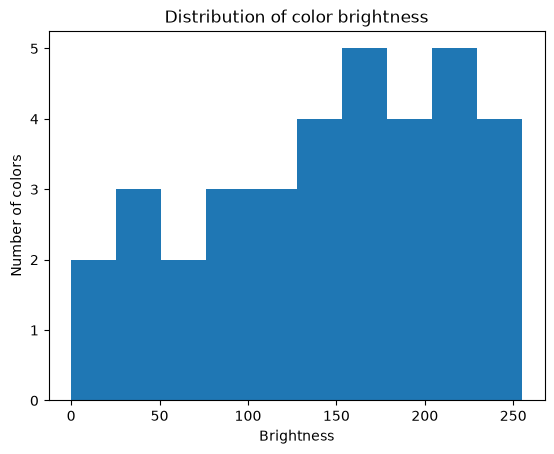

In [8]:
plt.hist(df["brightness"], bins=10)
plt.title("Distribution of color brightness")
plt.xlabel("Brightness")
plt.ylabel("Number of colors")
plt.show()

To see how the number of bins changes the picture, I drew the same data with 5, 10, and 20 bins side by side. Comparing the three charts side-by-side was a suggestion that Claude gave me and help me figure out how to code.

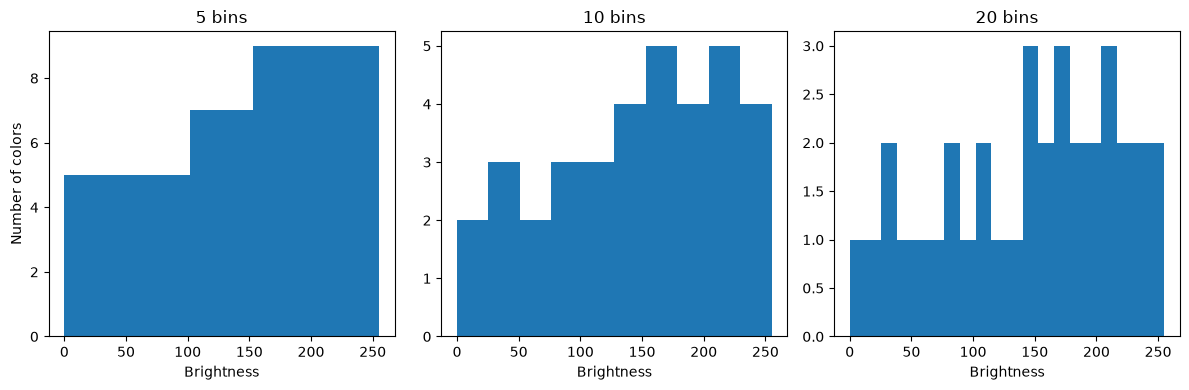

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, n_bins in zip(axes, [5, 10, 20]):
    ax.hist(df["brightness"], bins=n_bins)
    ax.set_title(f"{n_bins} bins")
    ax.set_xlabel("Brightness")

axes[0].set_ylabel("Number of colors")
plt.tight_layout()
plt.show()

In [10]:
print("Mean:  ", round(df["brightness"].mean(), 1))
print("Median:", round(df["brightness"].median(), 1))
print("Skew:  ", round(df["brightness"].skew(), 2))

Mean:   145.2
Median: 159.9
Skew:   -0.38


**What the figure shows:** how bright the 35 colors are, from black (0) on the left to white (255) on the right.
This is useful as a first look before comparing groups.

**What does the distribution look like?** The colors are spread across the whole range, but more of them
fall on the bright side. The median (159.9) is higher than the mean (145.2), and the skew is negative (-0.38),
so the distribution is slightly **left-skewed**: a smaller number of very dark colors (Black, Navy, Blue,
Indigo, Maroon) pull the mean down.

**Unusual values or patterns?** There are no extreme outliers since brightness can't go past 0 or 255.
One interesting pattern is a group of very light colors with brightness above 220 (White, Ivory,
Beige, Lavender, Yellow, Khaki). Many of these are pale "tint" colors, which are popular color names.

**How do the bins affect the chart?** With **5 bins**, the bars are so wide that the chart just says "more
bright colors than dark ones" and hides the details. With **20 bins**, most bars hold only 1 to 3 colors, so
the chart looks bumpy and the gaps are just random. **10 bins** is the best balance for only 35 colors.

### Scatter plot: Red vs. Blue

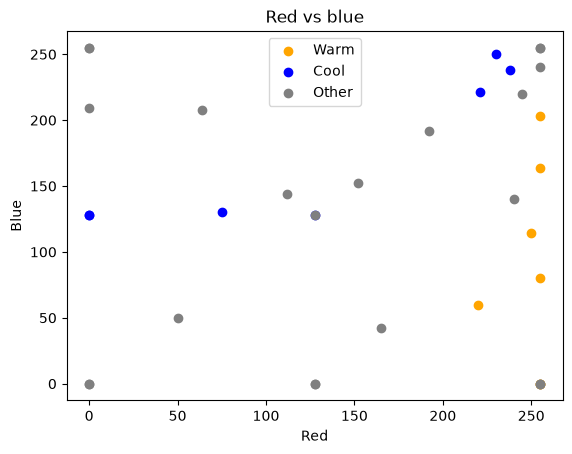

In [11]:
warm = df[df["category"] == "Warm"]
cool = df[df["category"] == "Cool"]
other = df[~df["category"].isin(["Warm", "Cool"])]

plt.scatter(warm["red"], warm["blue"], color="orange", label="Warm")
plt.scatter(cool["red"], cool["blue"], color="blue", label="Cool")
plt.scatter(other["red"], other["blue"], color="gray", label="Other")

plt.title("Red vs blue")
plt.xlabel("Red")
plt.ylabel("Blue")
plt.legend()
plt.show()

In [12]:
print("Correlation (red vs blue, all colors):", round(df["red"].corr(df["blue"]), 3))

Correlation (red vs blue, all colors): 0.049


**What the figure shows:** each color's amount of red (x-axis) against its amount of blue (y-axis), with warm
and cool colors in different colors. This helps explain *what* makes a color warm or cool in the data.

**Patterns:** Across all 35 colors there is almost no relationship between red and blue (r = 0.05), because
the dataset includes every kind of color. But the warm and cool groups separate very clearly. **Every warm color
has more red than blue**, so the orange points all sit in the lower right. **Every cool color has at least as
much blue as red**, so the blue points sit higher up on the left side. Warm colors also all have high red
(220 or more), while cool colors are spread out from very low (Navy, Teal) to very high (Lavender, Violet).

### Boxplot: Brightness by category

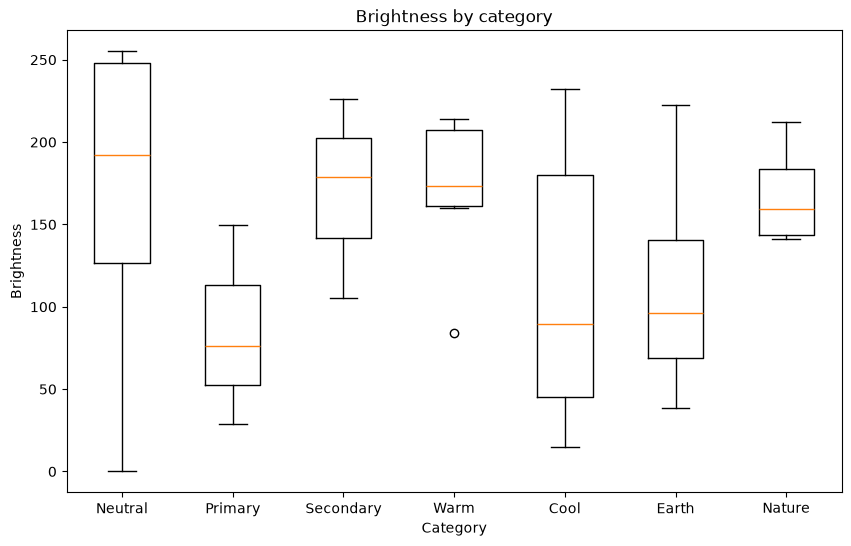

In [13]:
categories = df["category"].unique()

brightness_by_category = [
    df.loc[df["category"] == category, "brightness"]
    for category in categories
]

plt.figure(figsize=(10, 6))
plt.boxplot(brightness_by_category, tick_labels=categories)
plt.title("Brightness by category")
plt.xlabel("Category")
plt.ylabel("Brightness")
plt.show()

**What the figure shows:** the brightness of each category, including the median (orange line), the middle 50%
(box), and the full range (whiskers).

**What it reveals:** The **Warm** box sits clearly higher than the **Cool** box. The median warm color has a
brightness of 173.1 compared to only 89.7 for cool colors. Cool colors are also much more spread out: their box
and whiskers stretch from very dark (Navy, 14.6) to very light (Lavender, 232.3). Warm colors are bunched more
tightly, with every warm color except Crimson above 155. **Neutral** has the widest range of all, which makes
sense because it includes both Black and White. **Primary** has the lowest median, because pure Red and Blue are
fairly dark to the human eye. One limit of this chart is that some categories have only 3 or 4 colors, so their
boxes are based on very little data.

---
## Part 3: Improving the Visualizations

For a consistent look, all final figures use the **ggplot** style sheet, the same font sizes, and the
same two main colors: **coral** for warm and **steel blue** for cool. Whenever I show an individual color as a dot,
I fill it with its **actual hex color**, so I can see the colors myself.

In [21]:
plt.style.use("ggplot")

plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.titleweight"] = "bold"

WARM_COLOR = "#E4572E"
COOL_COLOR = "#2E86AB"

### Improved histogram

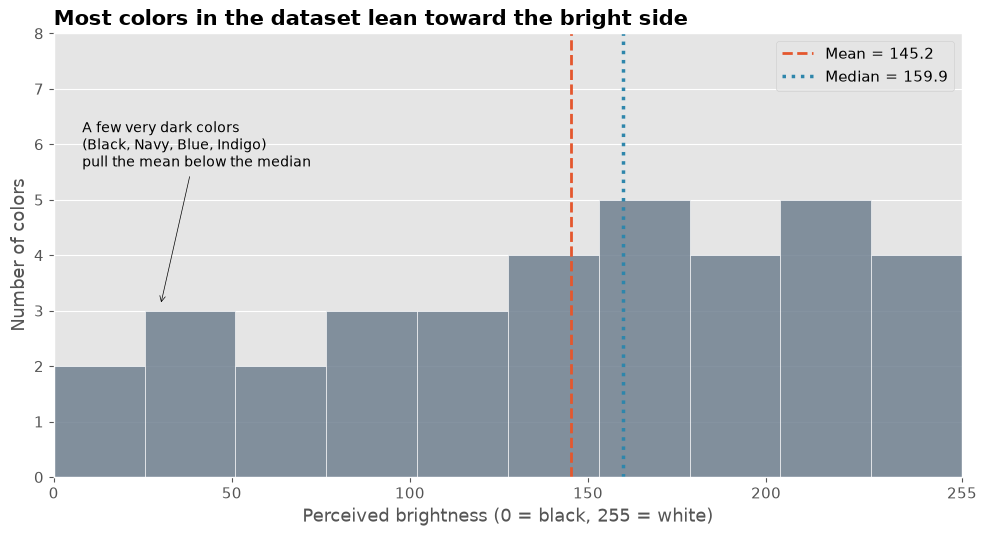

In [15]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.hist(
    df["brightness"],
    bins=10,
    range=(0, 255),
    color="slategray",
    edgecolor="white",
    alpha=0.85
)

mean_b = df["brightness"].mean()
median_b = df["brightness"].median()

ax.axvline(mean_b, color=WARM_COLOR, linestyle="--", linewidth=2, label=f"Mean = {mean_b:.1f}")
ax.axvline(median_b, color=COOL_COLOR, linestyle=":", linewidth=2.5, label=f"Median = {median_b:.1f}")

ax.annotate(
    "A few very dark colors\n(Black, Navy, Blue, Indigo)\npull the mean below the median",
    xy=(30, 3.1),
    xytext=(8, 5.6),
    arrowprops={"arrowstyle": "->", "color": "black"},
    fontsize=10
)

ax.set_title("Most colors in the dataset lean toward the bright side", loc="left")
ax.set_xlabel("Perceived brightness (0 = black, 255 = white)")
ax.set_ylabel("Number of colors")
ax.set_xlim(0, 255)
ax.set_xticks([0, 50, 100, 150, 200, 255])
ax.set_ylim(0, 8)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

### Improved scatter plot
* This is another section that Claude helped me with to play around with the different styles.

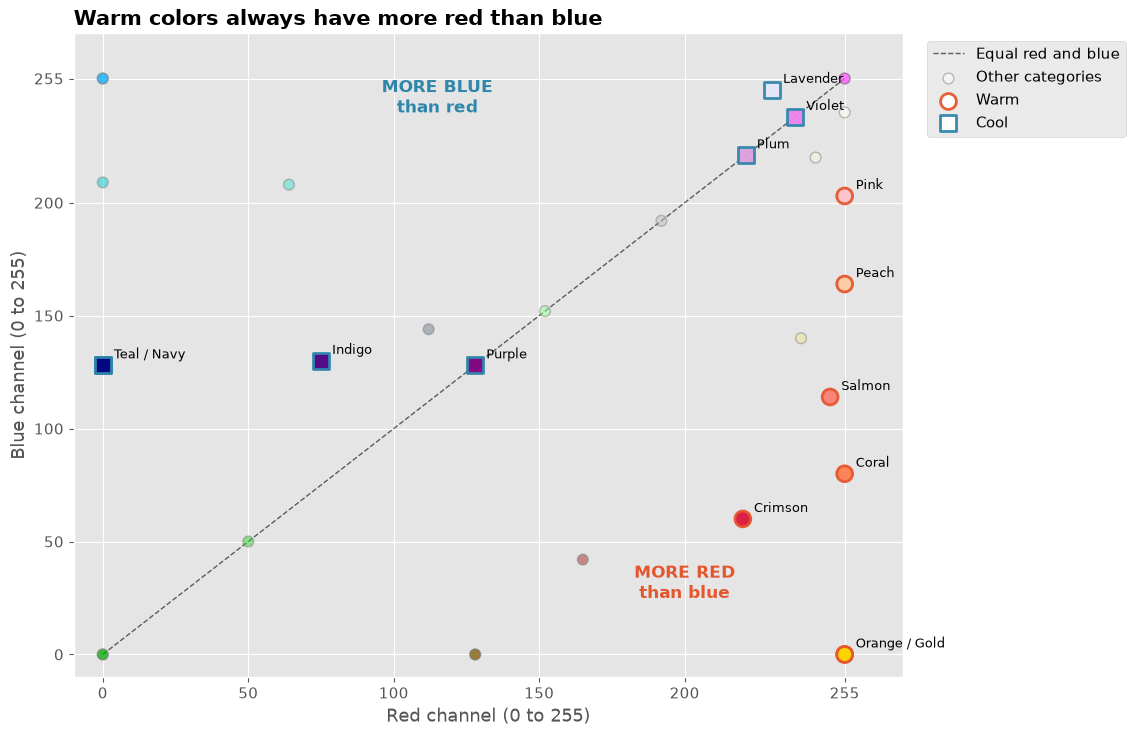

In [16]:
fig, ax = plt.subplots(figsize=(11.5, 7.5))

ax.plot([0, 255], [0, 255], color="black", linestyle="--", linewidth=1, alpha=0.6,
        label="Equal red and blue")

groups = [
    (other, "o", "gray", "Other categories"),
    (warm, "o", WARM_COLOR, "Warm"),
    (cool, "s", COOL_COLOR, "Cool"),
]

for data, marker, edge, label in groups:
    ax.scatter(
        data["red"],
        data["blue"],
        c=data["hex"],
        marker=marker,
        s=130 if label != "Other categories" else 60,
        edgecolors=edge,
        linewidths=2 if label != "Other categories" else 1,
        alpha=0.95 if label != "Other categories" else 0.5,
        label=label,
        zorder=3
    )

# Some colors share the same red/blue values (e.g., Navy and Teal), so their names are combined
labeled = pd.concat([warm, cool]).groupby(["red", "blue"])["name"].apply(" / ".join).reset_index()
for _, row in labeled.iterrows():
    ax.annotate(row["name"], xy=(row["red"], row["blue"]),
                xytext=(8, 5), textcoords="offset points", fontsize=9)

ax.text(200, 25, "MORE RED\nthan blue", color=WARM_COLOR, fontsize=12, fontweight="bold", ha="center")
ax.text(115, 240, "MORE BLUE\nthan red", color=COOL_COLOR, fontsize=12, fontweight="bold", ha="center")

ax.set_title("Warm colors always have more red than blue", loc="left")
ax.set_xlabel("Red channel (0 to 255)")
ax.set_ylabel("Blue channel (0 to 255)")
ax.set_xlim(-10, 275)
ax.set_ylim(-10, 275)
ax.set_xticks([0, 50, 100, 150, 200, 255])
ax.set_yticks([0, 50, 100, 150, 200, 255])

legend = ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
for handle in legend.legend_handles[1:]:   # skip the dashed line
    handle.set_facecolor("white")

plt.tight_layout()
plt.show()

### Improved boxplots
* Again, Claude helped me play around with and figure out the styles for this chart.

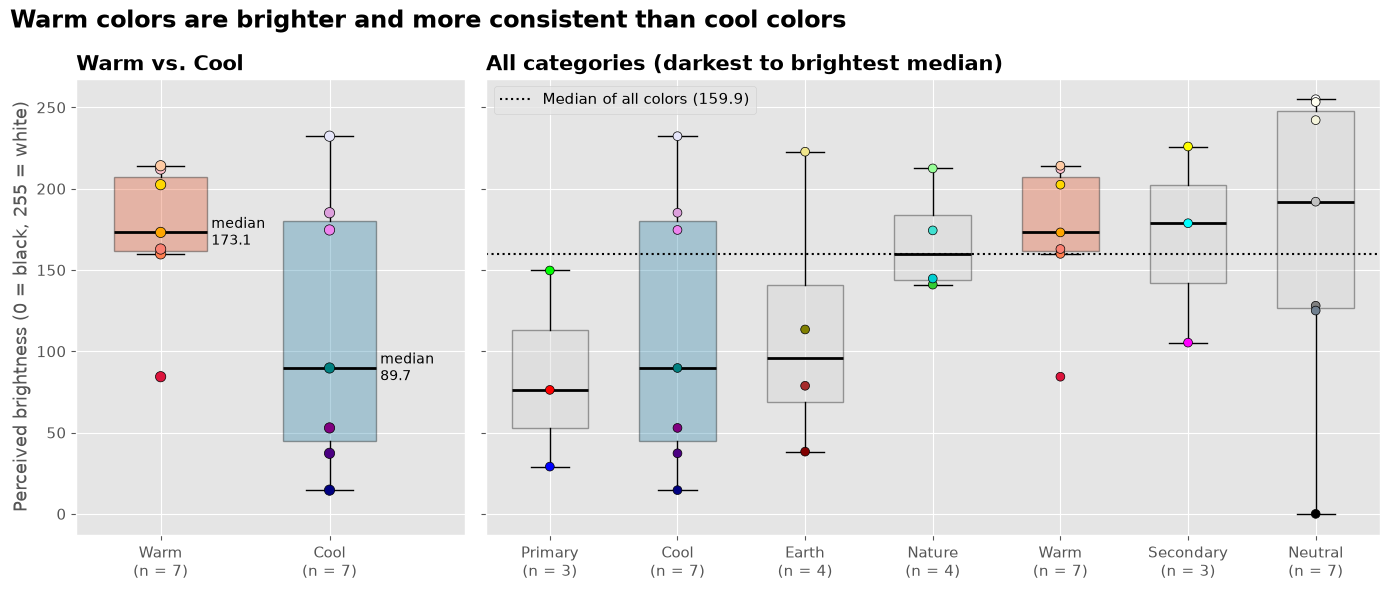

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6),
                               gridspec_kw={"width_ratios": [1, 2.3]}, sharey=True)

# ---- Left: Warm vs Cool
pair = [warm["brightness"], cool["brightness"]]
box = ax1.boxplot(pair, tick_labels=["Warm\n(n = 7)", "Cool\n(n = 7)"],
                  patch_artist=True, widths=0.55, showfliers=False,
                  medianprops={"color": "black", "linewidth": 2})

for patch, color in zip(box["boxes"], [WARM_COLOR, COOL_COLOR]):
    patch.set_facecolor(color)
    patch.set_alpha(0.35)

for i, data in enumerate([warm, cool], start=1):
    ax1.scatter([i] * len(data), data["brightness"], c=data["hex"],
                edgecolors="black", s=55, zorder=3)

for i, values in enumerate(pair, start=1):
    ax1.annotate(f"median\n{values.median():.1f}", xy=(i + 0.3, values.median()),
                 fontsize=10, va="center")

ax1.set_title("Warm vs. Cool", loc="left")
ax1.set_ylabel("Perceived brightness (0 = black, 255 = white)")
ax1.set_xlim(0.5, 2.8)

# ---- Right: every category, sorted from darkest to brightest median
order = df.groupby("category")["brightness"].median().sort_values().index
cat_data = [df.loc[df["category"] == c, "brightness"] for c in order]
labels = [f"{c}\n(n = {len(d)})" for c, d in zip(order, cat_data)]

box2 = ax2.boxplot(cat_data, tick_labels=labels, patch_artist=True, widths=0.6, showfliers=False,
                   medianprops={"color": "black", "linewidth": 2})

for patch, c in zip(box2["boxes"], order):
    if c == "Warm":
        patch.set_facecolor(WARM_COLOR)
    elif c == "Cool":
        patch.set_facecolor(COOL_COLOR)
    else:
        patch.set_facecolor("lightgray")
    patch.set_alpha(0.35)

for i, c in enumerate(order, start=1):
    data = df[df["category"] == c]
    ax2.scatter([i] * len(data), data["brightness"], c=data["hex"],
                edgecolors="black", s=40, zorder=3)

ax2.axhline(df["brightness"].median(), color="black", linestyle=":", linewidth=1.5,
            label=f"Median of all colors ({df['brightness'].median():.1f})")
ax2.set_title("All categories (darkest to brightest median)", loc="left")
ax2.legend(loc="upper left")

fig.suptitle("Warm colors are brighter and more consistent than cool colors",
             fontsize=17, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Design decisions
* This is a section where claude helped me to figure out making a table, which I ended up needing a lot of help troubleshooting. 

| What I changed | Why | How it helps the viewer |
|---|---|---|
| Applied the **ggplot style sheet** with `plt.style.use()` and set shared font sizes | The default charts looked plain and each one looked a little different | All three figures now look like they belong to the same report |
| Made figures larger with **`figsize`** | The defaults were small and the labels were crowded | Text, dots, and annotations are easier to read |
| Wrote **titles that state the finding** (e.g., "Warm colors always have more red than blue") | Titles like "Red vs blue" don't say what to notice | Viewers know the main point before they study the chart |
| Added **units and scales to axis labels** (e.g., "0 = black, 255 = white") | "Brightness" alone doesn't tell the viewer what the numbers mean | Someone who has never seen the data can still read the axes |
| Used **consistent colors**: coral for warm, steel blue for cool, gray for everything else | In the first drafts, colors were picked at random | The same color always means the same group across all figures |
| **Filled each dot with its real hex color** and used different **markers** (circles vs. squares) | Seeing the actual colors makes the data much more intuitive | Viewers can see that the cool group really does contain both dark navy and pale lavender |
| Used **transparency (`alpha`)** on boxes and "other" points | Boxes and dots were covering each other | The warm and cool points stand out while everything stays visible |
| Added **reference lines**: mean and median in the histogram, an "equal red and blue" line in the scatter plot, and the overall median in the boxplot | Viewers need something to compare against | The diagonal line shows exactly where the warm/cool split happens |
| Added **annotations**: color names, median values, and an arrow explaining the skew | Important details were easy to miss | Viewers don't have to guess which dot is which or what the median is |
| Set **axis limits and tick marks** (0 to 255) | The default ticks stopped at odd numbers | The full possible range is shown, so the scale is honest |
| **Removed vertical gridlines** in the histogram | They cut through the bars without adding information | A cleaner chart that keeps attention on the bars |
| Used **subplots** for the boxplots | One chart couldn't show both the main comparison and the full picture | Viewers see the answer to my question (left) and the context (right) together |
| Sorted categories by median and added **sample sizes** to the labels | The first boxplot was in a random order and hid how small some groups were | It is easy to compare categories and to see that some have only 3 colors |
| Used **`tight_layout()`** | Labels and titles were getting cut off | Everything fits inside the figure |

---
## Part 4: Statistical Analysis

### Option A: Comparing two groups with OLS

- **Dependent variable (Y):** brightness
- **Independent variable (X):** category (Warm vs. Cool only)

I only keep the warm and cool colors for this model, since those are the two groups in my research question. This is another section where I needed a lot of help from Claude, since I haven't taken a statistics class since 2017.

In [18]:
warm_cool = df[df["category"].isin(["Warm", "Cool"])]

warm_cool.groupby("category")["brightness"].agg(
    ["count", "mean", "median", "std"]
).round(1)

,count,mean,median,std
category,,,,
Cool,7,112.4,89.7,84.5
Warm,7,172.7,173.1,45.1


In [19]:
model_a = ols(
    "brightness ~ C(category)",
    data=warm_cool
).fit()

print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:             brightness   R-squared:                       0.188
Model:                            OLS   Adj. R-squared:                  0.120
Method:                 Least Squares   F-statistic:                     2.779
Date:                Mon, 09 Nov 2026   Prob (F-statistic):              0.121
Time:                        18:03:55   Log-Likelihood:                -77.801
No. Observations:                  14   AIC:                             159.6
Df Residuals:                      12   BIC:                             160.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             112.3580    

In [20]:
print("Intercept (Cool mean):", round(model_a.params["Intercept"], 2))
print("Warm coefficient:     ", round(model_a.params["C(category)[T.Warm]"], 2))
print("p-value:              ", round(model_a.pvalues["C(category)[T.Warm]"], 3))
print("R-squared:            ", round(model_a.rsquared, 3))

Intercept (Cool mean): 112.36
Warm coefficient:      60.34
p-value:               0.121
R-squared:             0.188


### Interpretation

- **Intercept = 112.36.** Because "Cool" comes first alphabetically, statsmodels uses it as the baseline group.
  The intercept is the average brightness of the cool colors.
- **Warm coefficient = +60.34.** On average, warm colors are about **60 points brighter** than cool colors
  (about 172.7 vs. 112.4 on the 0 to 255 scale). This matches the direction of my hypothesis.
- **p-value = 0.121.** This is **above 0.05**, so I **cannot reject the null hypothesis**. Even though the
  difference looks large, it is not statistically significant.
- **R² = 0.188.** Warm vs. cool explains about 19% of the variation in brightness among these 14 colors.
  The other 81% comes from differences inside each group.

**Does this support my hypothesis?** Only **partly**. The warm colors were brighter on average, which is the
direction I predicted, but the difference was not statistically significant. The main reason is visible in the
boxplot: the cool group is extremely spread out (standard deviation 84.5, from Navy at 14.6 to Lavender at 232.3),
and there are only 7 colors in each group. With that much variation and such small groups, a 60-point difference
could happen by chance.

### Limitations and assumptions

- **Small sample.** With only 7 colors per group, the test has very little power to detect a real difference.
- **OLS assumes similar spread in each group.** The cool group's spread (84.5) is almost twice the warm group's
  (45.1), so this assumption is not well met.
- **Independent, random sample.** OLS assumes the colors are a random sample. They aren't: someone chose which
  35 colors to include and which category to give each one.
- **The labels are subjective.** Only 14 of the 35 colors are labeled warm or cool. Colors like Red, Yellow,
  and Blue are labeled "primary" or "secondary" instead, even though most people would call them warm or cool.
- **The brightness formula is an estimate** of what an average person sees on a standard screen.

---
## Part 5: Conclusions and Reflection

**What did I learn?** Even a simple list of color names and RGB values holds a lot of information once you create
new variables from it. In this dataset, warm and cool colors are defined almost perfectly by one rule: warm colors
have more red than blue, and cool colors have at least as much blue as red. Warm colors were also brighter on
average (172.7 vs. 112.4) and much more consistent in brightness.

**Did the findings support my hypothesis?** Partly. The direction was correct, but the OLS model's p-value of
0.121 means the difference was not statistically significant, so I can't confidently say warm colors are brighter
in general.

**Which visualization was most effective?** The **boxplot** was the most effective for answering my research
question, because it shows both the higher median for warm colors *and* how widely the cool colors are spread,
which is the reason the test wasn't significant. The **scatter plot** was the most interesting, because filling
the dots with their real colors showed what makes a color "warm" or "cool" without needing any statistics.

**Did the statistics show anything the charts didn't?** Yes. Looking at the boxplot alone, I would have guessed
the difference was obviously real, since the warm box sits so much higher. The p-value showed that with only
7 colors per group and such a large spread among the cool colors, the difference could be due to chance. The
R² also showed that warm vs. cool explains only about a fifth of the variation in brightness.

**Limitations of the dataset and analysis:**
- Only 35 colors, and only 14 of them are labeled warm or cool.
- The categories were chosen by whoever made the dataset, and some are debatable (for example, Violet and Plum
  are "cool" but contain as much red as blue).
- The dataset isn't a random sample of colors, so the results may not apply to all colors.

**What the analysis might miss:**
- How bright a color looks depends on what's around it and on the screen showing it.
- People with color vision deficiencies see these colors differently.
- "Warm" and "cool" are partly about feeling and culture, not just RGB values.

**What could improve the investigation?**
- Use a **larger dataset**, such as the 140+ named colors supported by web browsers, to get bigger groups.
- **Label every color as warm or cool using a consistent rule** (for example, its position on the color wheel)
  instead of relying on the dataset's categories.
- Use a **regression with a quantitative predictor**, such as the amount of blue, to see how brightness changes
  as a color gets "cooler."
- Ask people to **rate** how bright and how warm each color feels, and compare their ratings to the formula.

**Summary:** My research question asked whether warm colors are brighter than cool colors. The histogram showed that
brightness varies widely across the dataset, the scatter plot showed that warm and cool colors are separated by their
balance of red and blue, and the boxplot showed warm colors with a much higher median brightness. The OLS model
confirmed that warm colors were about 60 points brighter on average, but with only 7 colors per group and a lot of
variation among the cool colors, the difference was not statistically significant (p = 0.121). The evidence leans
toward my hypothesis, but a larger dataset would be needed to support it with confidence.